In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [65]:
df=pd.read_csv("novagen_dataset.csv")

In [66]:
df.head()

,Age,BMI,Blood_Pressure,Cholesterol,Glucose_Level,Heart_Rate,Sleep_Hours,Exercise_Hours,Water_Intake,Stress_Level,...,Diet,MentalHealth,PhysicalActivity,MedicalHistory,Allergies,Diet_Type__Vegan,Diet_Type__Vegetarian,Blood_Group_AB,Blood_Group_B,Blood_Group_O
0,2.0,26.0,111.0,198.0,99.0,72.0,4.0,1.0,5.0,5.0,...,1,2,1,0,1,False,True,True,False,False
1,8.0,24.0,121.0,199.0,103.0,75.0,2.0,1.0,2.0,9.0,...,1,2,1,2,2,False,False,True,False,False
2,81.0,27.0,147.0,203.0,100.0,74.0,10.0,-0.0,5.0,1.0,...,2,0,0,1,0,True,False,False,False,False
3,25.0,21.0,150.0,199.0,102.0,70.0,7.0,3.0,3.0,3.0,...,1,2,1,2,0,True,False,False,True,False
4,24.0,26.0,146.0,202.0,99.0,76.0,10.0,2.0,5.0,1.0,...,2,0,2,0,2,False,True,False,True,False


In [67]:
df.isnull().sum()

Age                      0
BMI                      0
Blood_Pressure           0
Cholesterol              0
Glucose_Level            0
Heart_Rate               0
Sleep_Hours              0
Exercise_Hours           0
Water_Intake             0
Stress_Level             0
Target                   0
Smoking                  0
Alcohol                  0
Diet                     0
MentalHealth             0
PhysicalActivity         0
MedicalHistory           0
Allergies                0
Diet_Type__Vegan         0
Diet_Type__Vegetarian    0
Blood_Group_AB           0
Blood_Group_B            0
Blood_Group_O            0
dtype: int64

In [68]:
print(df.shape)
print(df['Target'].value_counts())
print(df['Target'].value_counts(normalize=True) * 100)

(9549, 23)
Target
1    4979
0    4570
Name: count, dtype: int64
Target
1    52.141586
0    47.858414
Name: proportion, dtype: float64


In [69]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df["Diet_Type__Vegan"]=le.fit_transform(df["Diet_Type__Vegan"])
df["Diet_Type__Vegetarian"]=le.fit_transform(df["Diet_Type__Vegetarian"])
df["Blood_Group_AB"]=le.fit_transform(df["Blood_Group_AB"])
df["Blood_Group_B"]=le.fit_transform(df["Blood_Group_B"])
df["Blood_Group_O"]=le.fit_transform(df["Blood_Group_O"])

<Axes: >

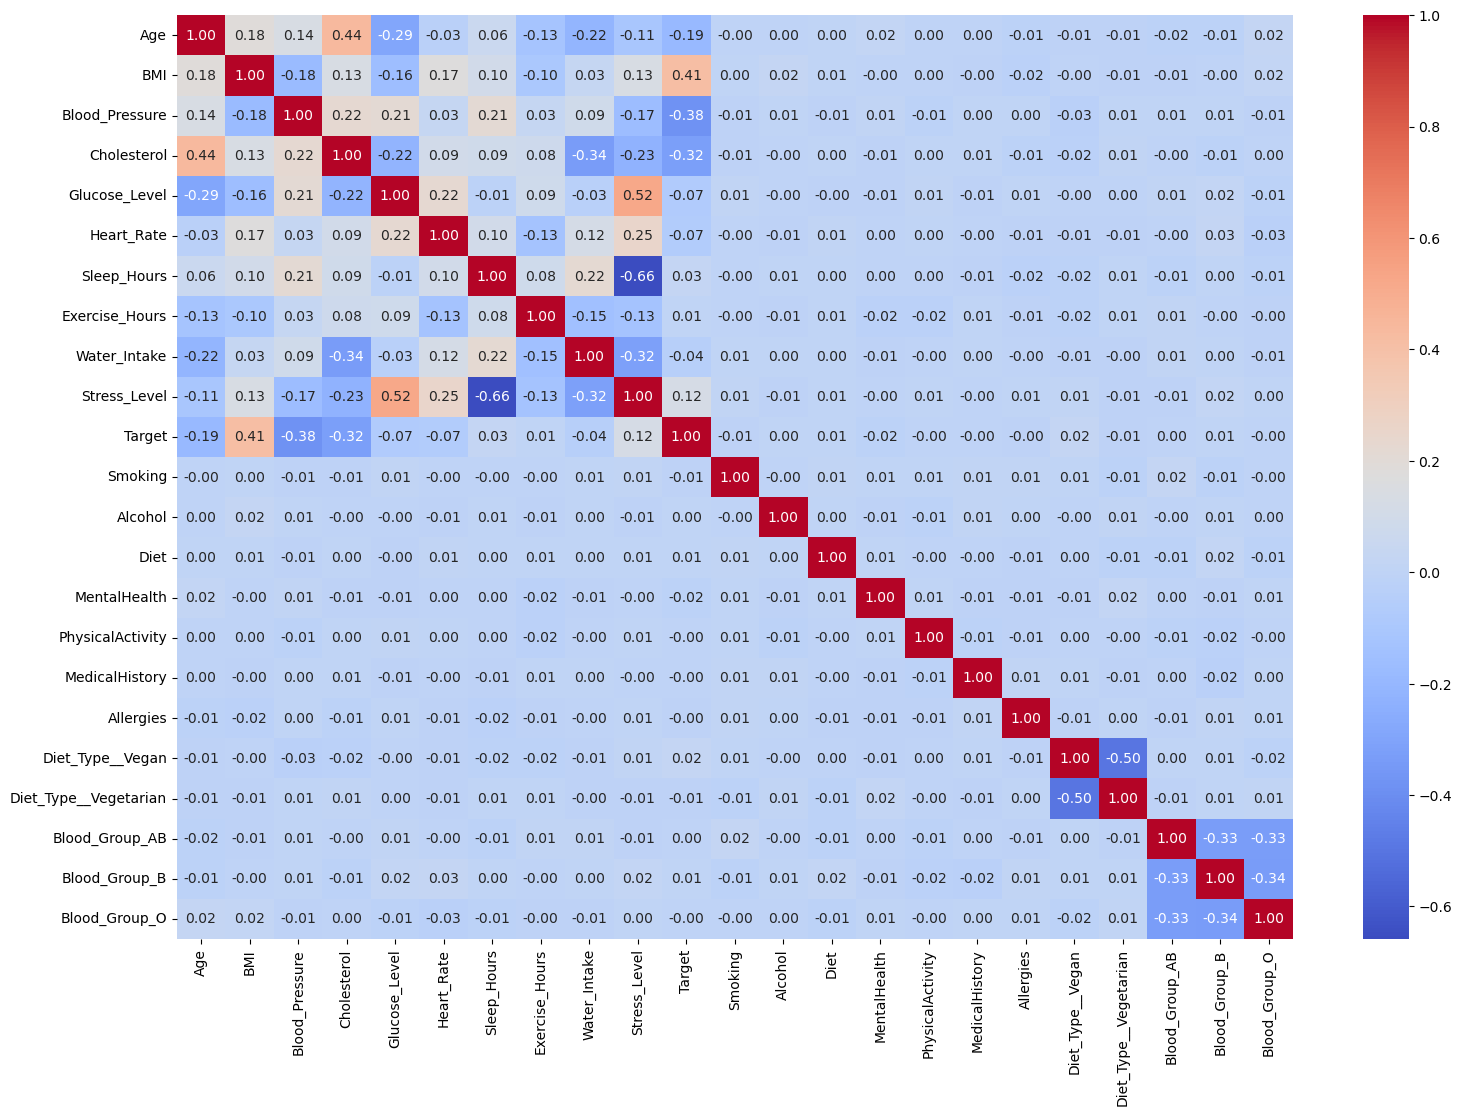

In [70]:
coor_matrix=df.corr()
plt.figure(figsize=(18,12))
sns.heatmap(
    coor_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
    
)

In [71]:

df.corr()["Target"].sort_values(ascending=False)

Target                   1.000000
BMI                      0.413972
Stress_Level             0.119455
Sleep_Hours              0.025931
Diet_Type__Vegan         0.023707
Exercise_Hours           0.008214
Blood_Group_B            0.007749
Diet                     0.005602
Alcohol                  0.003077
Blood_Group_AB           0.001174
MedicalHistory          -0.001666
PhysicalActivity        -0.002511
Blood_Group_O           -0.002728
Allergies               -0.004322
Diet_Type__Vegetarian   -0.005176
Smoking                 -0.005283
MentalHealth            -0.016372
Water_Intake            -0.038406
Heart_Rate              -0.065957
Glucose_Level           -0.072148
Age                     -0.190743
Cholesterol             -0.324361
Blood_Pressure          -0.380279
Name: Target, dtype: float64

In [103]:
df["BMI"]=df["BMI"]*2

In [104]:
X=df.drop("Target",axis=1)
y=df["Target"]

In [105]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [106]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [107]:
#LogisticRegression


In [108]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,precision_score,accuracy_score,recall_score,f1_score
log_reg=LogisticRegression()
log_reg.fit(X_train_scaled,y_train)
y_pred=log_reg.predict(X_test_scaled)
print("LogisticRegression Model")
print("confusion_matrix:",confusion_matrix(y_test,y_pred))
print("precision_score:",precision_score(y_test,y_pred))
print("accuracy_score:",accuracy_score(y_test,y_pred))
print("recall_score:",recall_score(y_test,y_pred))
print("f1_score:",f1_score(y_test,y_pred))

LogisticRegression Model
confusion_matrix: [[725 175]
 [164 846]]
precision_score: 0.8285994123408423
accuracy_score: 0.8225130890052356
recall_score: 0.8376237623762376
f1_score: 0.8330871491875923


In [109]:
#DecisionTreeClassifier

In [110]:
from sklearn.tree import DecisionTreeClassifier
dtc=DecisionTreeClassifier(max_depth=10,min_samples_split=4, min_samples_leaf=4)
dtc.fit(X_train_scaled,y_train)
y_pred=dtc.predict(X_test_scaled)
print("accuracy_score:",accuracy_score(y_test,y_pred))


accuracy_score: 0.8973821989528796


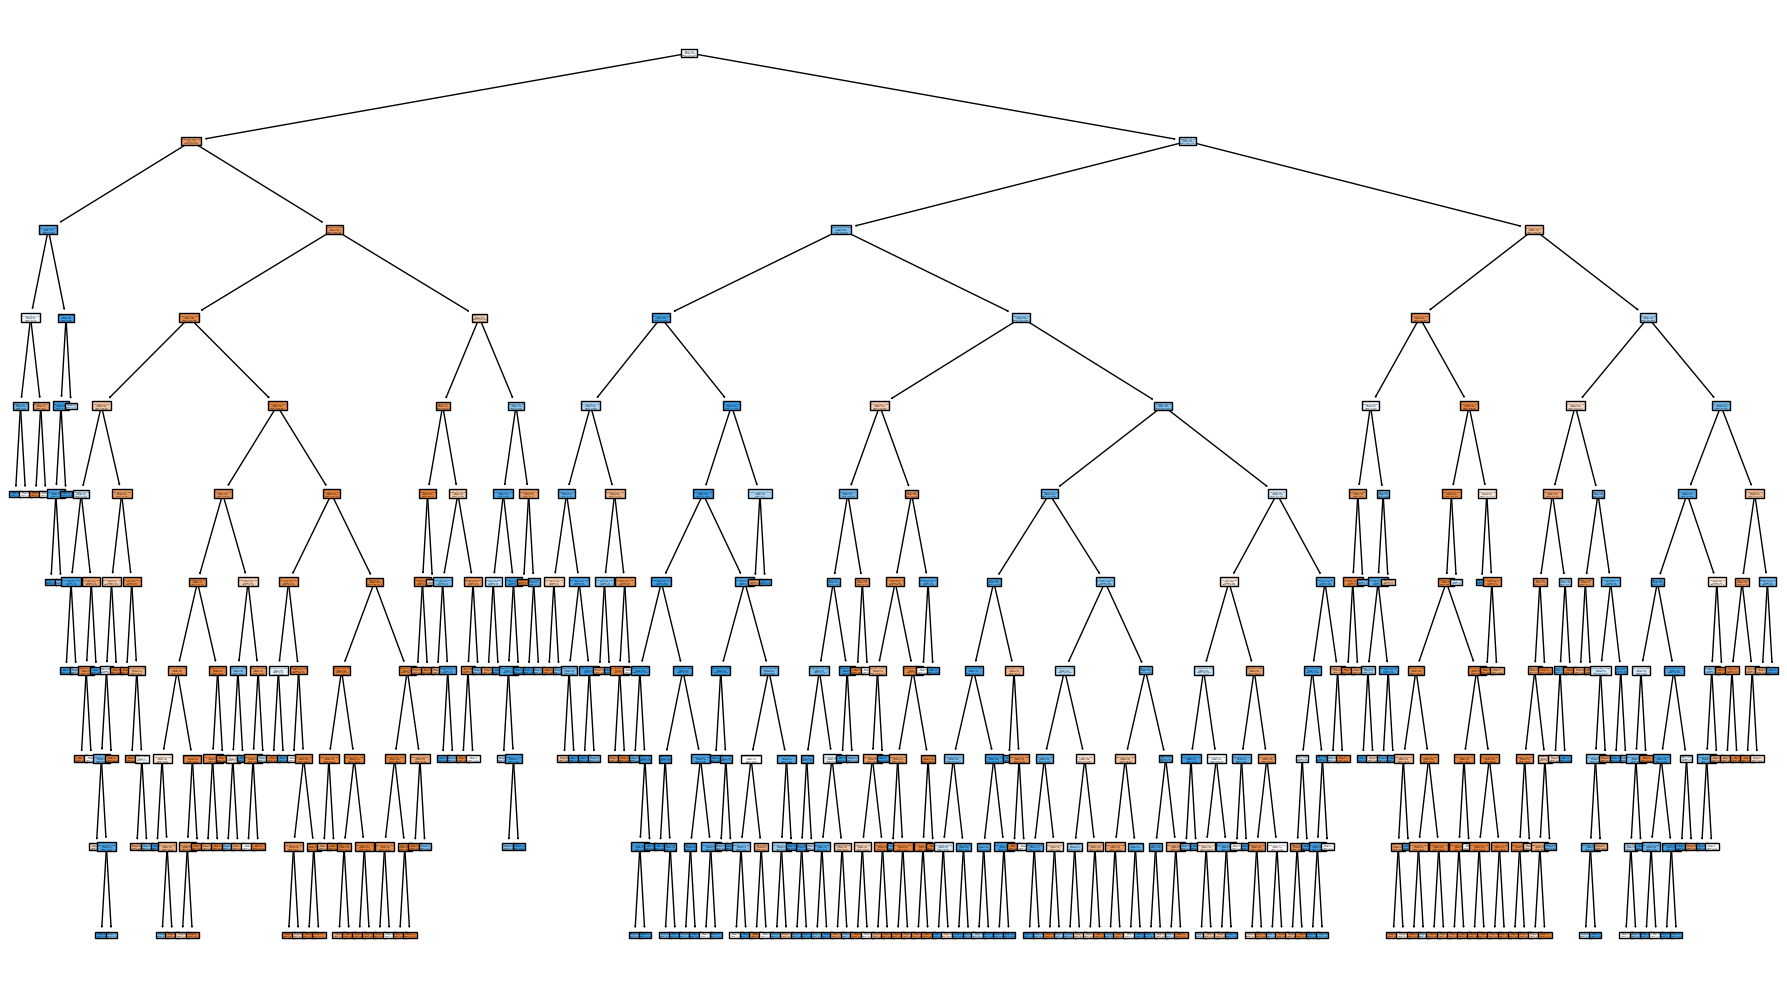

In [111]:
from sklearn.tree import plot_tree
plt.figure(figsize=(18,10))
plot_tree(
    dtc,
    feature_names=X.columns,
    class_names=["unhealthy","healthy"],
    filled=True
    
)
plt.tight_layout()
plt.show()

In [112]:
full_tree=DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train_scaled,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [113]:
path = full_tree.cost_complexity_pruning_path(X_train_scaled,y_train)
ccp_alphas=path.ccp_alphas
print(ccp_alphas)

[0.00000000e+00 6.46925051e-05 6.52616474e-05 6.53317059e-05
 8.41546201e-05 8.46116546e-05 8.56553198e-05 8.62325119e-05
 8.63809328e-05 8.63899280e-05 8.64158553e-05 8.65441957e-05
 8.66935012e-05 8.67078532e-05 8.71566270e-05 1.03549056e-04
 1.09089322e-04 1.10366715e-04 1.14543788e-04 1.16361944e-04
 1.17816468e-04 1.17816468e-04 1.17816468e-04 1.18439836e-04
 1.19006533e-04 1.19006533e-04 1.19998255e-04 1.19998255e-04
 1.19998255e-04 1.19998255e-04 1.19998255e-04 1.20434612e-04
 1.21556673e-04 1.22973418e-04 1.23206764e-04 1.23420607e-04
 1.23634565e-04 1.23734190e-04 1.24017335e-04 1.24673511e-04
 1.25452721e-04 1.25452721e-04 1.25564036e-04 1.25670899e-04
 1.25872295e-04 1.26023543e-04 1.26058772e-04 1.26515279e-04
 1.27270876e-04 1.27369155e-04 1.27425548e-04 1.27714329e-04
 1.27714329e-04 1.27862834e-04 1.28061378e-04 1.28179954e-04
 1.28314965e-04 1.28437240e-04 1.28480859e-04 1.28527056e-04
 1.28829295e-04 1.29270847e-04 1.29348768e-04 1.29501241e-04
 1.29602092e-04 1.297883

In [114]:
tree=[]
for alpha in ccp_alphas:
    model=DecisionTreeClassifier(max_depth=10,random_state=42,ccp_alpha=alpha)
    model.fit(X_train_scaled,y_train)
    
    tree.append((model,alpha))

In [115]:
best_acc=0
best_alpha=0
for model,alpha in tree:
    acc=model.score(X_test_scaled,y_test)
    if acc > best_acc:
        best_acc=acc
        best_alpha=alpha

In [116]:
best_acc

0.9089005235602095

In [117]:
best_model=DecisionTreeClassifier(random_state=42,ccp_alpha=best_alpha)
best_model.fit(X_train,y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


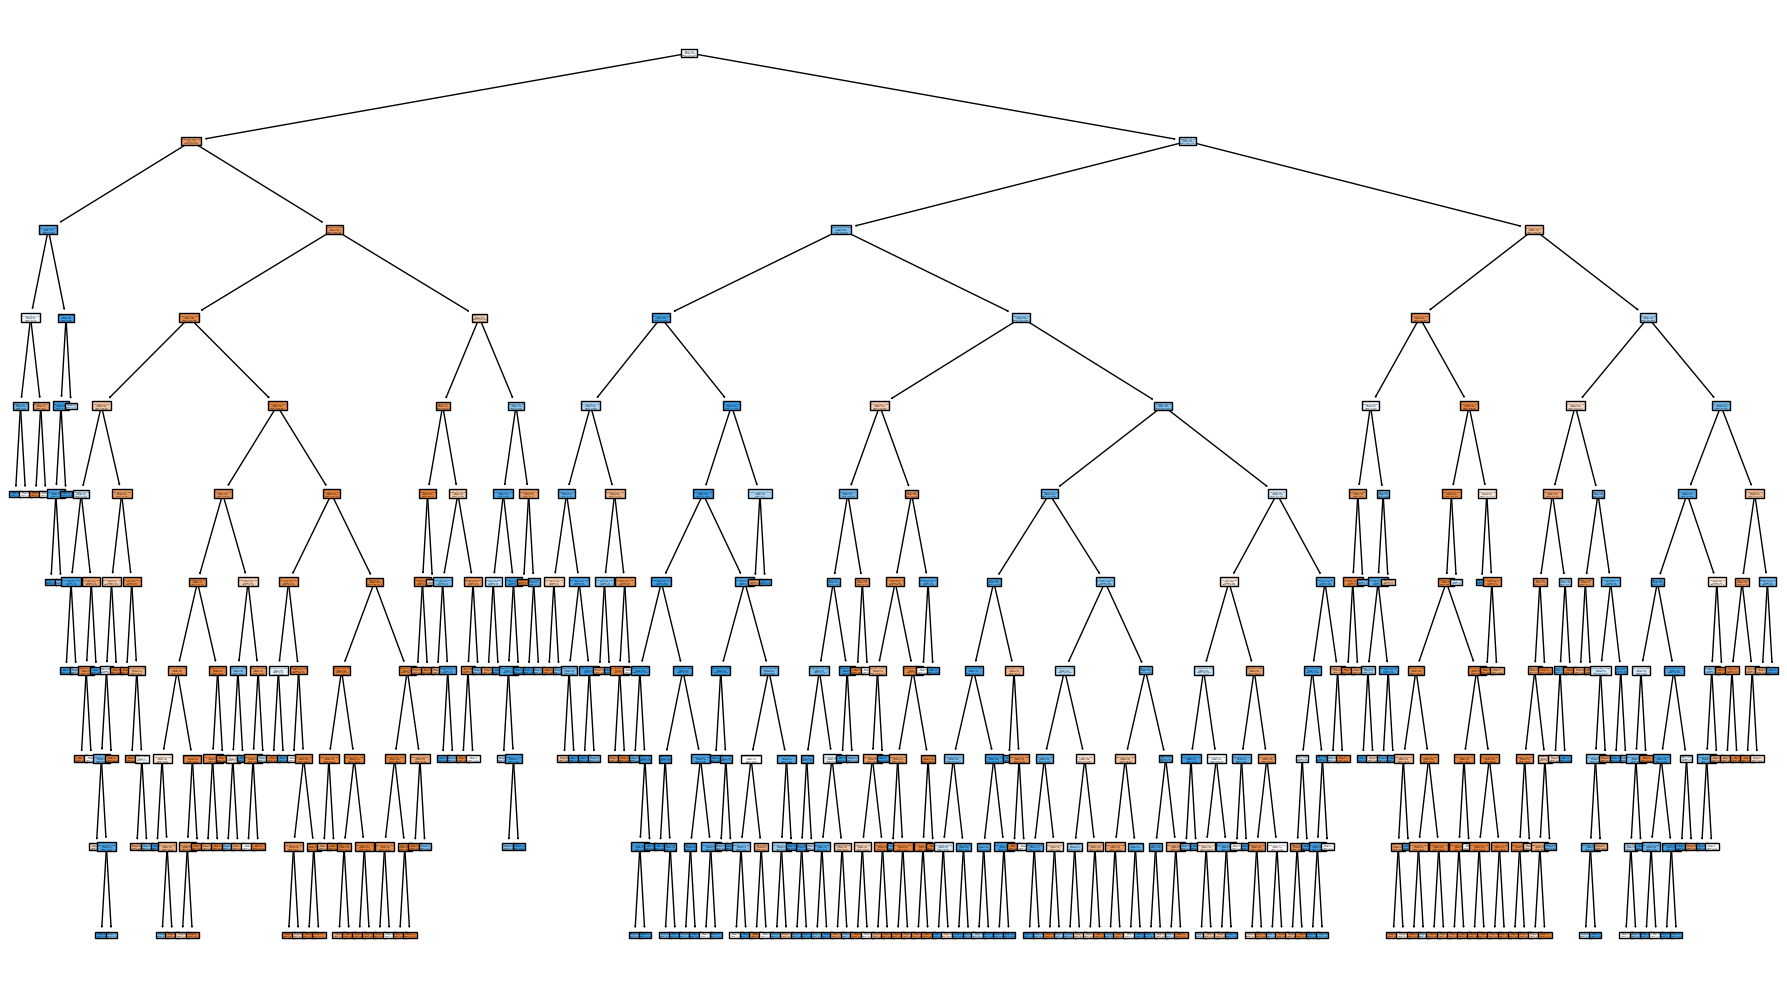

In [118]:
from sklearn.tree import plot_tree
plt.figure(figsize=(18,10))
plot_tree(
    dtc,
    feature_names=X.columns,
    class_names=["unhealthy","healthy"],
    filled=True
    
)
plt.tight_layout()
plt.show()

In [119]:
#RandomForestClassifier

In [120]:
from sklearn.ensemble import RandomForestClassifier
rfc=RandomForestClassifier(max_depth=10,n_estimators=501,oob_score=True)
rfc.fit(X_train_scaled,y_train)
y_pred=rfc.predict(X_test_scaled)
print("OOB_score",rfc.oob_score_)
print("testing accuracy:",accuracy_score(y_test,y_pred))

OOB_score 0.9264301610158397
testing accuracy: 0.9345549738219895
